<a href="https://colab.research.google.com/github/QuirozAlaniz/Hiperparametros/blob/main/Hiperparametros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Francisco Daniel Quiroz Alaniz
\
Matrícula: 269723


1. Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos

Declarar las bibliotecas necesarias para este proyecto
Cargar el conjunto de datos Glioma Grading Clinical and Mutation Features. Se puede descargar de https://archive.ics.uci.edu/dataset/759/glioma+grading+clinical+and+mutation+features+dataset

In [605]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, GridSearchCV

In [606]:
#Importación de datos
url = "/content/TCGA_GBM_LGG_Mutations_all.csv"

In [607]:
df = pd.read_csv(url)

2. 📊 Análisis exploratorio de datos (EDA)

Realiza un análisis inicial de los datos antes de modelar:

Describir forma y estructura (shape, describe(), info()).

Mostrar la distribución de clases (y.value_counts()).

Visualizar:

Histograma de al menos 3 variables numéricas.

Boxplots o violin plots por clase si es computacionalmente viable.

Mapa de calor de correlaciones entre variables.


In [608]:
#Describimos forma y estructura
df.shape

(862, 27)

Tenemos 862 filas y 27 columnas

In [609]:
df.describe()

,Grade,Project,Case_ID,Gender,Age_at_diagnosis,Primary_Diagnosis,Race,IDH1,TP53,ATRX,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
count,862,862,862,862,862,862,862,862,862,862,...,862,862,862,862,862,862,862,862,862,862
unique,2,2,862,3,838,7,6,2,2,2,...,2,2,2,2,2,2,2,2,2,2
top,LGG,TCGA-LGG,TCGA-DU-8164,Male,--,Glioblastoma,white,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
freq,499,499,1,499,5,360,766,448,508,642,...,815,821,824,833,834,834,835,839,839,840


In [610]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 862 entries, 0 to 861
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Grade              862 non-null    object
 1   Project            862 non-null    object
 2   Case_ID            862 non-null    object
 3   Gender             862 non-null    object
 4   Age_at_diagnosis   862 non-null    object
 5   Primary_Diagnosis  862 non-null    object
 6   Race               862 non-null    object
 7   IDH1               862 non-null    object
 8   TP53               862 non-null    object
 9   ATRX               862 non-null    object
 10  PTEN               862 non-null    object
 11  EGFR               862 non-null    object
 12  CIC                862 non-null    object
 13  MUC16              862 non-null    object
 14  PIK3CA             862 non-null    object
 15  NF1                862 non-null    object
 16  PIK3R1             862 non-null    object
 1

In [611]:
#Mostrar distribución de clases
df["Grade"].value_counts()

,count
Grade,
LGG,499
GBM,363


Casi no hay variables numéricas, la gran mayoría son categóricas
\
Observamos que hay 4 valores que son "--" en la columna "Age_at_diagnosis"
\
Como son solamente 4 de 862, procedemos a eliminarlas como filas.

In [612]:
df = df[df["Age_at_diagnosis"] != "--"]

In [613]:
df["Age_at_diagnosis"]

,Age_at_diagnosis
0,51 years 108 days
1,38 years 261 days
2,35 years 62 days
3,32 years 283 days
4,31 years 187 days
...,...
857,77 years 325 days
858,85 years 65 days
859,77 years 178 days
860,63 years 121 days


Esta columna la podemos separar para poder obtener una nueva columna que tenga solamente los años en enter con decima, es decir, float

In [614]:
#Generamos una nueva columna con los años incluyendo decimales

df[["años", "yers", "dias", "days"]] = df["Age_at_diagnosis"].str.split(expand = True)
df["años"] = pd.to_numeric(df["años"], errors = "coerce")
df["dias"] = df["dias"].astype(float)
df["años"] = (df["años"]*365 + df["dias"] )/365
print(df["años"])


0      51.295890
1      38.715068
2      35.169863
3      32.775342
4      31.512329
         ...    
857    77.890411
858    85.178082
859    77.487671
860    63.331507
861    76.605479
Name: años, Length: 857, dtype: float64


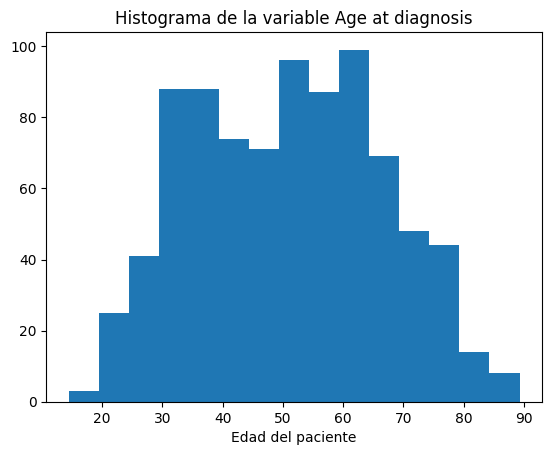

In [615]:
#Histograma
plt.figure()
plt.hist(df["años"], bins = 15)
plt.title("Histograma de la variable Age at diagnosis")
#plt.ylabel("Frecuencia")
plt.xlabel("Edad del paciente")
plt.show()

La gráfica se asemeja a una distribución Normal con datos concentrados entre 50 y 70.

([0, 1, 2, 3, 4],
 [Text(0, 0, 'white'),
  Text(1, 0, 'black or african american'),
  Text(2, 0, 'not reported'),
  Text(3, 0, 'asian'),
  Text(4, 0, 'american indian or alaska native')])

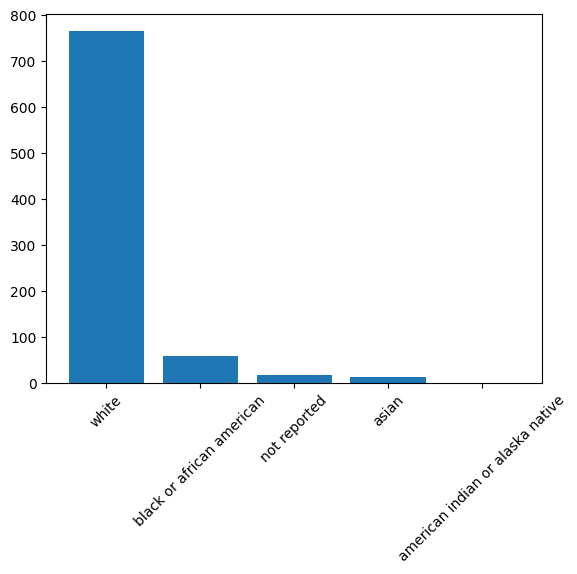

In [616]:
#Sustitución de histograma por gráfico de barras para variable "Race"
conteo_race = df["Race"].value_counts()
plt.figure()
plt.bar(conteo_race.index, conteo_race.values)
plt.xticks(rotation = 45)

Una de las características que están muy desbalanceadas es "Race" con una gran preponderancia de "white"

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'Glioblastoma'),
  Text(1, 0, 'Astrocytoma, anaplastic'),
  Text(2, 0, 'Mixed glioma'),
  Text(3, 0, 'Oligodendroglioma, NOS'),
  Text(4, 0, 'Oligodendroglioma, anaplastic'),
  Text(5, 0, 'Astrocytoma, NOS')])

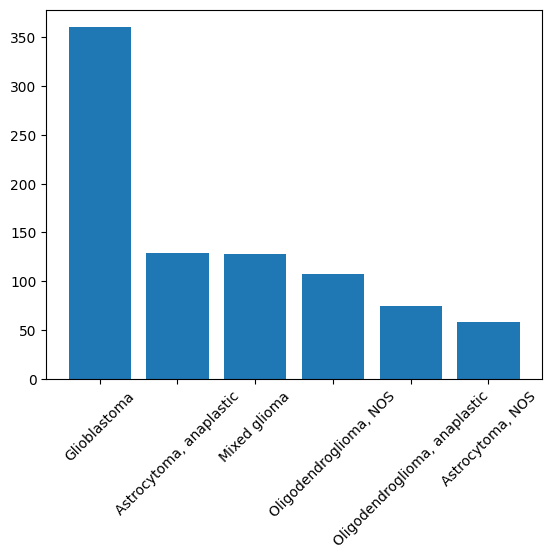

In [617]:
#Sustitución de histograma por gráfico de barras para variable "Primary Diagnosis"
conteo_race = df["Primary_Diagnosis"].value_counts()
plt.figure()
plt.bar(conteo_race.index, conteo_race.values)
plt.xticks(rotation = 45)

/tmp/ipykernel_1345/3879733526.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Grade', y='años', palette='Set2')


Text(0, 0.5, 'Edad (Años)')

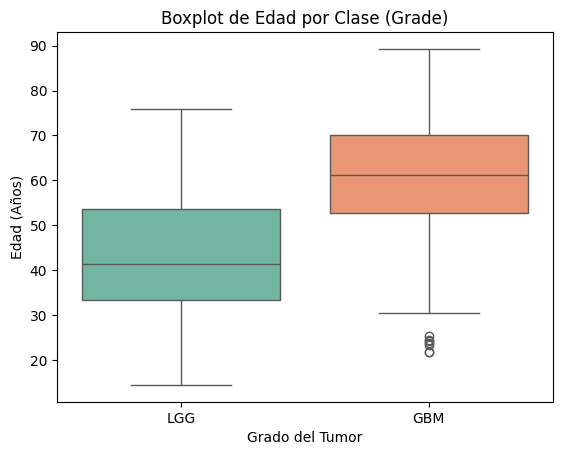

In [618]:
# B) Boxplot por clase (Edad de diagnóstico distribuido por Grade LGG vs GBM)
plt.figure()
sns.boxplot(data=df, x='Grade', y='años', palette='Set2')
plt.title('Boxplot de Edad por Clase (Grade)')
plt.xlabel('Grado del Tumor')
plt.ylabel('Edad (Años)')

Text(0.5, 1.0, 'Mapa de Calor: Correlación de Mutaciones Genéticas')

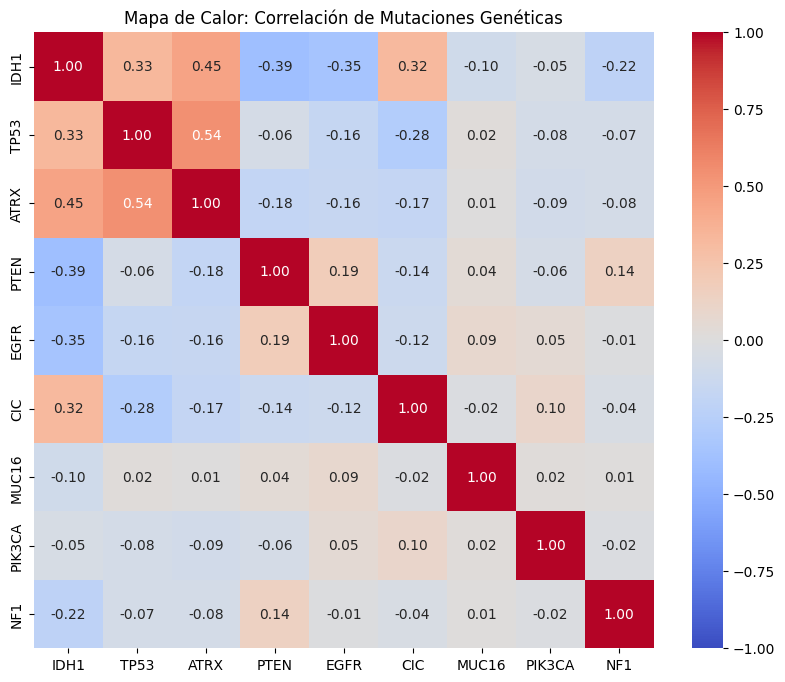

In [619]:
#Convertimos las columnas binarias (MUTATED y NO MUTATED) a 1 y 0 respectivamente
genes_a_analizar = ['IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'MUC16', 'PIK3CA', 'NF1']

# 3. Crear un nuevo DataFrame temporal convirtiendo 'MUTATED' en 1 y 'NOT_MUTATED' en 0
df_numerico = pd.DataFrame()
for gen in genes_a_analizar:
    df_numerico[gen] = df[gen].map({'MUTATED': 1, 'NOT_MUTATED': 0})

# 4. Calcular la matriz de correlación numérica
matriz_correlacion = df_numerico.corr()

# 5. Dibujar el mapa de calor
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Mapa de Calor: Correlación de Mutaciones Genéticas')


🧠 Reflexiona:

**¿Existen clases desbalanceadas?**
\
Las clases sí están desbalanceadas. Hay una mayor proporción de LG que de GG. Específicamente hay 57% de LGG y 43% de GBM

**¿Qué atributos parecen más informativos?**
\
Observando el boxplot podemos darnos cuenta que ambas: LGG y GBM parecen corresponder a edades muy específicas: LGG correspondería a edades entre 30 y poco más de 50 años de edad, mientras que GBM correspondería a paciente de 50 a 79 años.

3. Gráfica de Errores en Entrenamiento y Prueba

En este ejercicio vas a entrenar un árbol de decisión con diferentes profundidas. Asimismo, en gráfica mostrarás las exactitudes en entrenamiento y test, usando un stratified k-fold cross-validation con K= 10.

Los valores de las profundides a evaluar son 2, 5, 10, 15, 20, 25, 30 y None.

Deberás usar StratifiedKFold con 10 particiones, y un valor aleaotorio de 3.

Entrenarás y evaluarás un árbol de decisión con estos distintos valores de profundidades.

Usa cross_val_score para entrenar los modelos, usando como métrica de evaluación en scoring ="f1_macro", y el StratifiedKFold, con un valor aleatorio = 7

Muestra una gráfica para los distintos resultados  cuando se usa F1 Macro.

In [620]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score   #Porque es la métrica que vamos a usar para evaluar el modelo

Antes de realizar los pasos para dividir el dataset y entrenar el modelo hay que convertir las columnas de manera que solamente tengamos numéricas. Para esto usamos la siguiente conversión.

In [621]:
df_codificado = pd.get_dummies(df, columns=["Gender", "Race", "Primary_Diagnosis"])
df_codificado = df_codificado.replace({"MUTATED": True, "NOT_MUTATED":False})
df_codificado = df_codificado.replace({"GBM": True, "LGG":False})
df_codificado = df_codificado.replace({"Male": True, "Female":False})
df_codificado = df_codificado.replace({True: 1, False:0})
df_codificado = df_codificado.drop(columns = ["yers", "dias", "days"])


/tmp/ipykernel_1345/589909989.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_codificado = df_codificado.replace({"MUTATED": True, "NOT_MUTATED":False})
/tmp/ipykernel_1345/589909989.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_codificado = df_codificado.replace({"GBM": True, "LGG":False})
/tmp/ipykernel_1345/589909989.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-i

In [622]:
#Hacemos la separación de los datos en X, y
X = df_codificado.drop(columns = ["Grade", "Project", "Case_ID", "Age_at_diagnosis"])
y = df_codificado["Grade"]

#División del dataset en entrenamiento y prueba.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [623]:
#Configuramos el validador cruzado
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

In [624]:
#Definimos las profundidades
depths = [2, 5, 10, 15, 20, 25, 30, None]


In [625]:
#Definir el ciclo for para cada valor de profundidad
train_accuracies = []
test_accuracies = []
for depth in depths:
  clf = DecisionTreeClassifier(max_depth = depth, random_state = 7)
  scores_tests = cross_val_score(clf, X, y, cv=cv, scoring="f1_macro")
  test_accuracies.append(np.mean(scores_tests))

  clf.fit(X, y)
  pred_train = clf.predict(X)
  score_train = f1_score(y, pred_train, average="macro") # Usamos macro para igualar la métrica
  train_accuracies.append(score_train)


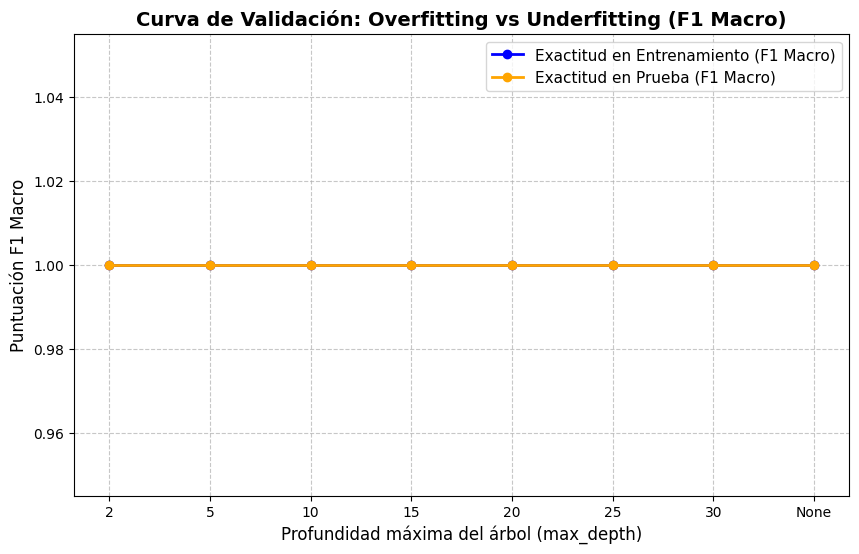

In [626]:
depths_labels = [str(d) for d in depths]
plt.figure(figsize=(10, 6))

# 3. Dibujar la línea de entrenamiento y la de prueba
plt.plot(depths_labels, train_accuracies, label='Exactitud en Entrenamiento (F1 Macro)', marker='o', color='blue', linewidth=2)
plt.plot(depths_labels, test_accuracies, label='Exactitud en Prueba (F1 Macro)', marker='o', color='orange', linewidth=2)

# 4. Personalizar etiquetas, títulos y leyendas
plt.xlabel('Profundidad máxima del árbol (max_depth)', fontsize=12)
plt.ylabel('Puntuación F1 Macro', fontsize=12)
plt.title('Curva de Validación: Overfitting vs Underfitting (F1 Macro)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)

In [627]:
train_accuracies = []
test_accuracies = []
depths = (2, 5, 10, 15, 20, 25, 30, None)

for depth in depths:
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
    clf.fit(X_train, y_train)
    train_accuracies.append(f1_score(y_train, clf.predict(X_train), average= "macro"))
    test_accuracies.append(f1_score(y_test, clf.predict(X_test), average="macro"))

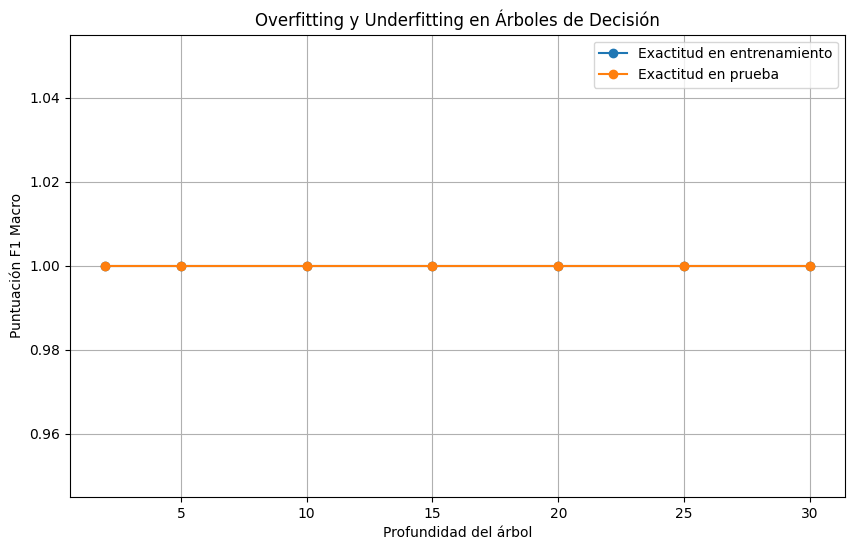

In [628]:
plt.figure(figsize=(10,6))
plt.plot(depths, train_accuracies, label='Exactitud en entrenamiento', marker='o')
plt.plot(depths, test_accuracies, label='Exactitud en prueba', marker='o')
plt.xlabel('Profundidad del árbol')
plt.ylabel('Puntuación F1 Macro')
plt.title('Overfitting y Underfitting en Árboles de Decisión')
plt.legend()
plt.grid(True)
plt.show()

4. Optimización de hiperparámetros con RandomizedSearchCV

Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
Criterion = gini ,entropy, max_depth: de 5 a 50 con incrementos de 1,  min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión
StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)

n_iter = 5 (combinaciones aleatorias a buscar)

n_jobs = -1 para acelerar cómputo

Métrica de evaluación: f1 Macro

Imprime los mejores hiperparámetros encontrados

Imprime el best_score

In [629]:
#Los datos son los globales X, y

# 2. Definir modelo base
clf = DecisionTreeClassifier(random_state=42)

# 3. Definir espacio de búsqueda
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

# 4. Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 5. Configurar búsqueda aleatoria
random_search = RandomizedSearchCV(estimator=clf, param_distributions=param_dist, n_iter=5, cv=cv, scoring='f1_macro', random_state=42, n_jobs=-1)

# 6. Ajustar el modelo
random_search.fit(X, y)

# 7. Resultados
print("Mejores hiperparámetros encontrados:", random_search.best_params_)
print("Best_score", random_search.best_score_)


Mejores hiperparámetros encontrados: {'min_samples_split': 7, 'max_depth': 18, 'criterion': 'entropy'}
Best_score 1.0


5. Optimización de hiperparámetros con GridSearchCV

Define el espacio de búsqueda  para los siguientes hiperpárametros:

Criterion = gini ,entropy

max_depth: de 5 a 50 con incrementos de 1

min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)

Métrica de evaluación: f1 Macro

n_jobs = -1 para acelerar cómputo

Imprime los mejores hiperparámetros encontrados

Imprime el best_score

In [630]:
#Los datos son los globales X, y

# 2. Definir modelo base
clf = DecisionTreeClassifier(random_state=42)

# 3. Definir espacio de búsqueda
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

# 4. Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 5. Configurar búsqueda aleatoria
grid_search = GridSearchCV(estimator=clf, param_grid=param_dist, cv=cv, scoring='f1_macro', n_jobs=-1)

# 6. Ajustar el modelo
grid_search.fit(X, y)

# 7. Resultados
print("Mejores hiperparámetros encontrados:", grid_search.best_params_)
print("Best_score", grid_search.best_score_)

Mejores hiperparámetros encontrados: {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 2}
Best_score 1.0


6. Optimización de hiperparámetros con RandomizedSearchCV: Accuracy

Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:

Criterion = gini ,entropy

max_depth: de 5 a 50 con incrementos de 1

min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión

StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
n_iter = 5 (combinaciones aleatorias a buscar)
n_jobs = -1 para acelerar cómputo

Métrica de evaluación: accuracy

Imprime los mejores hiperparámetros encontrados

Imprime el best_score

In [631]:
#Los datos son los globales X, y

# 2. Definir modelo base
clf = DecisionTreeClassifier(random_state=42)

# 3. Definir espacio de búsqueda
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

# 4. Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 5. Configurar búsqueda aleatoria
random_search = RandomizedSearchCV(estimator=clf, param_distributions=param_dist, n_iter=5, cv=cv, scoring='accuracy', random_state=42, n_jobs=-1)

# 6. Ajustar el modelo
random_search.fit(X, y)

# 7. Resultados
print("Mejores hiperparámetros encontrados:", random_search.best_params_)
print("Best_score", random_search.best_score_)


Mejores hiperparámetros encontrados: {'min_samples_split': 7, 'max_depth': 18, 'criterion': 'entropy'}
Best_score 1.0


7. Optimización de hiperparámetros con GridSearchCV: accuracy

Define el espacio de búsqueda  para los siguientes hiperpárametros:

Criterion = gini ,entropy

max_depth: de 5 a 50 con incrementos de 1

min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión

StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)

Métrica de evaluación: f1 Macro

n_jobs = -1 para acelerar cómputo

Imprime los mejores hiperparámetros encontrados

Imprime el best_score

In [632]:
#Los datos son los globales X, y

# 2. Definir modelo base
clf = DecisionTreeClassifier(random_state=42)

# 3. Definir espacio de búsqueda
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

# 4. Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 5. Configurar búsqueda aleatoria
grid_search = GridSearchCV(estimator=clf, param_grid=param_dist, cv=cv, scoring='accuracy', n_jobs=-1)

# 6. Ajustar el modelo
grid_search.fit(X, y)

# 7. Resultados
print("Mejores hiperparámetros encontrados:", grid_search.best_params_)
print("Best_score", grid_search.best_score_)

Mejores hiperparámetros encontrados: {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 2}
Best_score 1.0


8.Actividad de reflexión y análisis

**¿Cuál método encontró mejores hiperparámetros?**
\
El método que encontró los mejores hiperparámetros fue GridSearchCV porque encontró el mejor modelo con una profundidad máxima de 5, mientras que RandomizedSearchCV lo encontró en la profundidad 18(solución más compleja). Por otro lado, GridSearchCV encontró el mejor modelo usando el criterio de "gini", mientras que RandomizedSearchCV con "entropy"

**¿Cuál fue más costoso computacionalmente?**
\
El más costoso computacionalmente hablando es GridSearchCV porque no trabaja sobre una muestra sino sobre todas las combinaciones posibles de hiperparámetros. De hecho en tiempo se puede ver, tomando varios minutos, mientras que RandomizedSearchCV, al trabajar solo en una muestra, el código corre en cuestión de algunos segundos.

**¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?**
\
Pudimos observar que f1_macro arrojó exactamente el mismo resultado como best_score con 1 en ambos modelos.  

**¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?**
\
\
Podemos ver que en ambos métodos de optimización que coincidieron al usar "accuracy" como score, obtuvimos exactamente los mismos resultados en el best_score.

**¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro?**
\
No, son diferentes.
\
Al usar accuracy obtuvimos en RandomizedSearchCV: min_samples_split= 4, max_depth= 18, criterion= entropy.
\
Al usar accuracy en GridSearchCV, obtuvimos: criterion= gini, max_depth= 5, min_samples_split= 2.
\
De igual forma, difiere al usar f1_macro.

Es muy curioso que alcancen los cuatro modelos una exactitud de 1, por lo que probablemente hay "data leakage".

Podemos observar que la columna de "Grade" y la columna transformada "Primary_Diagnosis_Glioblastoma" son idénticas, por lo que probablemente sea esta columna "Primary_Diagnosis" la que esté causando el data leakage.
\
\
Por lo tanto a continuación se presenta todo el procedimiento completo solo que quitando esa columna.

In [633]:
df = pd.read_csv(url)
df = df[df["Age_at_diagnosis"] != "--"]
df = df.drop(columns = ["Primary_Diagnosis"])

In [634]:
df_codificado = pd.get_dummies(df, columns=["Gender", "Race"])
df_codificado = df_codificado.replace({"MUTATED": True, "NOT_MUTATED":False})
df_codificado = df_codificado.replace({"GBM": True, "LGG":False})
df_codificado = df_codificado.replace({"Male": True, "Female":False})
df_codificado = df_codificado.replace({True: 1, False:0})

/tmp/ipykernel_1345/1974574328.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_codificado = df_codificado.replace({"MUTATED": True, "NOT_MUTATED":False})
/tmp/ipykernel_1345/1974574328.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_codificado = df_codificado.replace({"GBM": True, "LGG":False})
/tmp/ipykernel_1345/1974574328.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To op

In [635]:
#Hacemos la separación de los datos en X, y
X = df_codificado.drop(columns = ["Grade", "Project", "Case_ID", "Age_at_diagnosis"])
y = df_codificado["Grade"]

#División del dataset en entrenamiento y prueba.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [636]:
#Configuramos el validador cruzado
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

In [637]:
#Definimos las profundidades
depths = [2, 5, 10, 15, 20, 25, 30, None]

In [638]:
#Definir el ciclo for para cada valor de profundidad
train_accuracies = []
test_accuracies = []
for depth in depths:
  clf = DecisionTreeClassifier(max_depth = depth, random_state = 7)
  scores_tests = cross_val_score(clf, X, y, cv=cv, scoring="f1_macro")
  test_accuracies.append(np.mean(scores_tests))

  clf.fit(X, y)
  pred_train = clf.predict(X)
  score_train = f1_score(y, pred_train, average="macro") # Usamos macro para igualar la métrica
  train_accuracies.append(score_train)

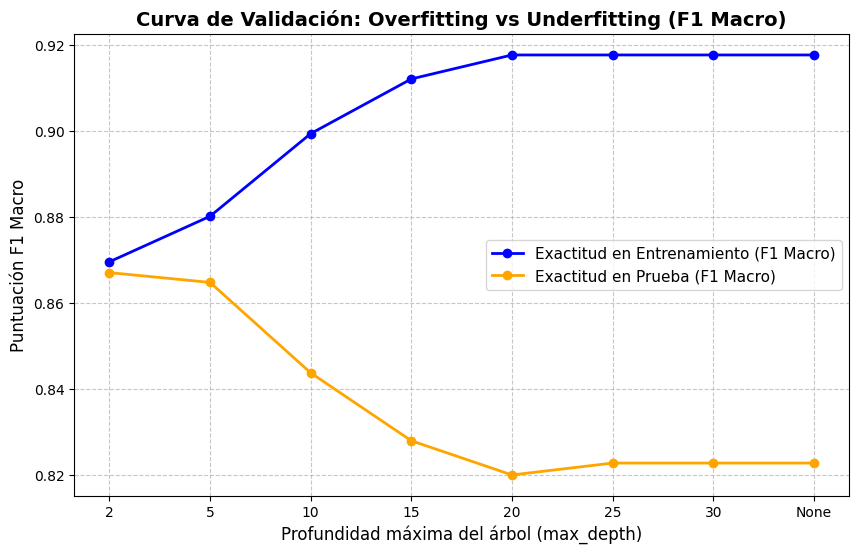

In [639]:
depths_labels = [str(d) for d in depths]
plt.figure(figsize=(10, 6))

# 3. Dibujar la línea de entrenamiento y la de prueba
plt.plot(depths_labels, train_accuracies, label='Exactitud en Entrenamiento (F1 Macro)', marker='o', color='blue', linewidth=2)
plt.plot(depths_labels, test_accuracies, label='Exactitud en Prueba (F1 Macro)', marker='o', color='orange', linewidth=2)

# 4. Personalizar etiquetas, títulos y leyendas
plt.xlabel('Profundidad máxima del árbol (max_depth)', fontsize=12)
plt.ylabel('Puntuación F1 Macro', fontsize=12)
plt.title('Curva de Validación: Overfitting vs Underfitting (F1 Macro)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)

In [640]:
train_accuracies = []
test_accuracies = []
depths = (2, 5, 10, 15, 20, 25, 30, None)

for depth in depths:
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
    clf.fit(X_train, y_train)
    train_accuracies.append(f1_score(y_train, clf.predict(X_train), average= "macro"))
    test_accuracies.append(f1_score(y_test, clf.predict(X_test), average="macro"))

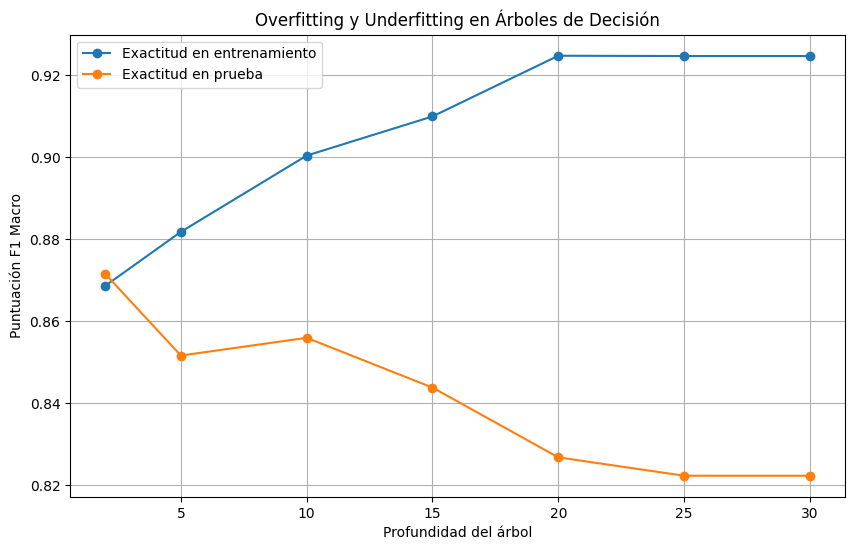

In [641]:
plt.figure(figsize=(10,6))
plt.plot(depths, train_accuracies, label='Exactitud en entrenamiento', marker='o')
plt.plot(depths, test_accuracies, label='Exactitud en prueba', marker='o')
plt.xlabel('Profundidad del árbol')
plt.ylabel('Puntuación F1 Macro')
plt.title('Overfitting y Underfitting en Árboles de Decisión')
plt.legend()
plt.grid(True)
plt.show()

**4. Optimización de hiperparámetros con RandomizedSearchCV**

In [642]:
#Los datos son los globales X, y

# 2. Definir modelo base
clf = DecisionTreeClassifier(random_state=42)

# 3. Definir espacio de búsqueda
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

# 4. Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 5. Configurar búsqueda aleatoria
random_search = RandomizedSearchCV(estimator=clf, param_distributions=param_dist, n_iter=5, cv=cv, scoring='f1_macro', random_state=42, n_jobs=-1)

# 6. Ajustar el modelo
random_search.fit(X, y)

# 7. Resultados
print("Mejores hiperparámetros encontrados:", random_search.best_params_)
print("Best_score", random_search.best_score_)

Mejores hiperparámetros encontrados: {'min_samples_split': 11, 'max_depth': 18, 'criterion': 'entropy'}
Best_score 0.8286961316345008


**5. Optimización de hiperparámetros con GridSearchCV**

In [643]:
#Los datos son los globales X, y

# 2. Definir modelo base
clf = DecisionTreeClassifier(random_state=42)

# 3. Definir espacio de búsqueda
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

# 4. Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 5. Configurar búsqueda aleatoria
grid_search = GridSearchCV(estimator=clf, param_grid=param_dist, cv=cv, scoring='f1_macro', n_jobs=-1)

# 6. Ajustar el modelo
grid_search.fit(X, y)

# 7. Resultados
print("Mejores hiperparámetros encontrados:", grid_search.best_params_)
print("Best_score", grid_search.best_score_)

Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 15}
Best_score 0.8716352848581188


**6. Optimización de hiperparámetros con RandomizedSearchCV: Accuracy**

In [644]:
#Los datos son los globales X, y

# 2. Definir modelo base
clf = DecisionTreeClassifier(random_state=42)

# 3. Definir espacio de búsqueda
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

# 4. Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 5. Configurar búsqueda aleatoria
random_search = RandomizedSearchCV(estimator=clf, param_distributions=param_dist, n_iter=5, cv=cv, scoring='accuracy', random_state=42, n_jobs=-1)

# 6. Ajustar el modelo
random_search.fit(X, y)

# 7. Resultados
print("Mejores hiperparámetros encontrados:", random_search.best_params_)
print("Best_score", random_search.best_score_)


Mejores hiperparámetros encontrados: {'min_samples_split': 11, 'max_depth': 18, 'criterion': 'entropy'}
Best_score 0.8331190150478797


**7. Optimización de hiperparámetros con GridSearchCV: accuracy**

In [645]:
#Los datos son los globales X, y

# 2. Definir modelo base
clf = DecisionTreeClassifier(random_state=42)

# 3. Definir espacio de búsqueda
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 51),
    'min_samples_split': range(2, 21)
}

# 4. Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 5. Configurar búsqueda aleatoria
grid_search = GridSearchCV(estimator=clf, param_grid=param_dist, cv=cv, scoring='accuracy', n_jobs=-1)

# 6. Ajustar el modelo
grid_search.fit(X, y)

# 7. Resultados
print("Mejores hiperparámetros encontrados:", grid_search.best_params_)
print("Best_score", grid_search.best_score_)

Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 15}
Best_score 0.8728180574555404


8.Actividad de reflexión y análisis

**¿Cuál método encontró mejores hiperparámetros?**
\
El modelo que encontró los mejores hiperparámetros fue GridSearchCV con una exactitud de 0.8728 y parámetros de máxima profundidad de 5 bajo el criterio de entropía. Este es el mejor resultado de todos, pues los demás estuvieron por debajo de esta exactitud.

**¿Cuál fue más costoso computacionalmente?**
\
El más costoso computacionalmente hablando es GridSearchCV porque no trabaja sobre una muestra sino sobre todas las combinaciones posibles de hiperparámetros. De hecho en tiempo se puede ver, tomando varios minutos, mientras que RandomizedSearchCV, al trabajar solo en una muestra, el código corre en cuestión de algunos segundos.

**¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?**
\
GridSearchCV alcanzó un Best_score de 0.8716. RandomizedSearchCV se quedó abajo con un Best_score de 0.8286.
Esto ocurrió probablemente porque al limpiar la variable que causaba filtración de datos, las reglas de decisión de los árboles se volvieron más complejas al aprender de más columnas (variables).  

**¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?**
\
\
Sí, también se observaron discrepancias similares.
\
GridSearchCV obtuvo un accuracy de 0.8728 mientras que RandomizedSearchCV obtuvo un accuracy de 0.8331.
\

**¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro?**
\
En RandomizedSearchCV, tanto con F1 Macro como con Accuracy, el modelo fue: min_samples_split= 11, max_depth= 18, criterion= entropy.
\
En GridSearchCV, tanto con F1 Macro como con Accuracy, el modelo fue: criterion= entropy, max_depth= 5, min_samples_split= 15.
\
Es decir, sí fueron iguales a excepción de la profundidad máxima.